# Random Forest: от одного дерева к ансамблю

Исследуем, почему деревья меняются при изменении данных, что исправляет усреднение и как выбирать параметры случайного леса.

1. **Одно дерево:** реализовать регрессионный пень и сравнить глубины.
2. **Бэггинг:** сгенерировать bootstrap-выборки, обучить деревья и усреднить прогнозы.
3. **Смещение и разброс:** измерить компоненты ошибки по повторным обучениям.
4. **Random Forest:** выбрать параметры в ограниченном бюджете и один раз оценить итоговую модель на test.

Ориентир для практики — 12 + 15 + 13 + 20 минут. Теория включена перед заданиями. Все графики и организация экспериментов готовы; ячейки **ВАШ КОД** нужно заполнить. Незаполненные функции выводят напоминание, ошибки в реализации проверки не скрывают.

Задания 3 и 4 можно выполнять независимо от первых двух. Для строгого разложения ошибки используем регрессию с квадратичной потерей. Данные синтетические: сначала одномерная функция для визуализации, затем многомерная задача для настройки леса. Нужны NumPy, Matplotlib, scikit-learn и Jupyter.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import mean_squared_error
from IPython.display import display, HTML

SEED = 42
BLUE, ORANGE, GREEN, RED = '#2563eb', '#ea580c', '#059669', '#dc2626'
plt.rcParams.update({'figure.figsize':(10,4), 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.grid':True, 'grid.alpha':.16})

def table(rows):
    import html
    if not rows: return
    columns=list(rows[0])
    def fmt(value):
        return f'{value:.4f}' if isinstance(value,(float,np.floating)) else str(value)
    head=''.join(f'<th>{html.escape(str(k))}</th>' for k in columns)
    body=''.join('<tr>'+''.join(f'<td>{html.escape(fmt(row[k]))}</td>' for k in columns)+'</tr>' for row in rows)
    display(HTML('<table><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table>'))

def rmse(y,pred):
    return float(np.sqrt(mean_squared_error(y,pred)))

def truth(x):
    return np.sin(2*x)+.3*x

NOISE = .35

def draw_data(n, rng):
    X=rng.uniform(-3,3,size=(n,1))
    y=truth(X[:,0])+rng.normal(0,NOISE,size=n)
    return X,y

X_grid=np.linspace(-3,3,200)[:,None]
f_grid=truth(X_grid[:,0])
rng_data=np.random.default_rng(SEED)
X_train,y_train=draw_data(80,rng_data)
X_val,y_val=draw_data(400,rng_data)

print('Среда готова. Все данные генерируются локально.')

Среда готова. Все данные генерируются локально.


## 1. Одно дерево: лучший разрез и сложность
### 1.1. Как дерево решает задачу регрессии
В классификации лист хранит доли классов. В регрессии с квадратичной потерей лист хранит **среднее** ответов попавших в него обучающих объектов:
$$\hat y_R=\arg\min_c\sum_{i\in R}(y_i-c)^2=\frac1{|R|}\sum_{i\in R}y_i.$$
Производная суммы по $c$ равна $2\sum_i(c-y_i)$; приравняв её нулю, получаем среднее.

Для вопроса $x_j\le t$ выбираем минимальную сумму ошибок в двух детях:
$$SSE(t)=\sum_{i\in L}(y_i-\bar y_L)^2+\sum_{i\in R}(y_i-\bar y_R)^2.$$
Это эквивалентно максимальному уменьшению взвешенной дисперсии. Чем крупнее ребёнок, тем больше его вклад; нельзя усреднять ошибки детей поровну независимо от их размеров.

**Пень** — дерево глубины 1: один вопрос и два листа. Наивная реализация перебирает середины между соседними различными значениями признака.

### Задание
Реализуйте `fit_stump(x, y, min_leaf=1)`. На входе одномерные непустые массивы одинаковой длины. Верните `(threshold, left_value, right_value)`:
- каждый ребёнок содержит не менее `min_leaf` объектов;
- при равных значениях SSE берите меньший порог;
- если разрез невозможен, верните `(None, y.mean(), y.mean())`.

Используйте только NumPy. Для прогнозов слева всегда действует условие `x <= threshold`. Полная рекурсия дерева здесь не требуется: сосредоточимся на критерии и затем используем библиотечные деревья в ансамбле.

In [2]:
def fit_stump(x, y, min_leaf=1):
    # ВАШ КОД: допустимые пороги, средние в детях, минимальная сумма квадратов.
    raise NotImplementedError('Реализуйте fit_stump')

In [3]:
def predict_stump(model, x):
    threshold,left_value,right_value=model
    x=np.asarray(x)
    return np.full(x.shape,left_value) if threshold is None else np.where(x<=threshold,left_value,right_value)

stump_ready=False
try:
    assert np.allclose(fit_stump([0,1,2,3],[0,0,4,4]),[1.5,0,4])
    assert fit_stump([1,1,1],[0,2,4])==(None,2.,2.)
    assert fit_stump([0,1,2],[0,2,4],min_leaf=2)==(None,2.,2.)
    # При min_leaf=2 единственный допустимый порог — 1.5.
    assert fit_stump([0,1,2,3],[10,0,0,0],min_leaf=2)[0]==1.5
    assert fit_stump([0,1,2,3],[1,1,1,1])[0]==.5
    x=np.array([0,0,1,1,2,2],dtype=float);y=np.array([0,0,1,1,5,5],dtype=float)
    own=fit_stump(x,y)
    ref=DecisionTreeRegressor(max_depth=1,random_state=SEED).fit(x[:,None],y)
    probe=np.array([-.5,.5,1.5,2.5])
    assert np.allclose(predict_stump(own,probe),ref.predict(probe[:,None]))
    assert np.isclose(predict_stump((1.,2.,3.),np.array([1.]))[0],2.)
    stump_ready=True
    print('Проверены средние, повторяющиеся признаки, ограничения листа, пороги и сравнение со sklearn.')
except NotImplementedError as exc:
    print(exc)

Реализуйте fit_stump


### 1.2. Сравните глубины
Данные получены из известной функции $f(x)=\sin(2x)+0.3x$ с независимым шумом стандартного отклонения 0.35. На рисунке точки — train, чёрная линия — истинная функция, цветная — прогноз.

**До запуска:** какое дерево лучше опишет train? Какое окажется лучше на validation? Измените одну глубину и размер листа, затем объясните результат. Низкая ошибка train сама по себе не доказывает хорошего обобщения.

`max_depth=None` означает отсутствие ограничения глубины. Число листьев при этом всё ещё ограничено данными и другими условиями построения.

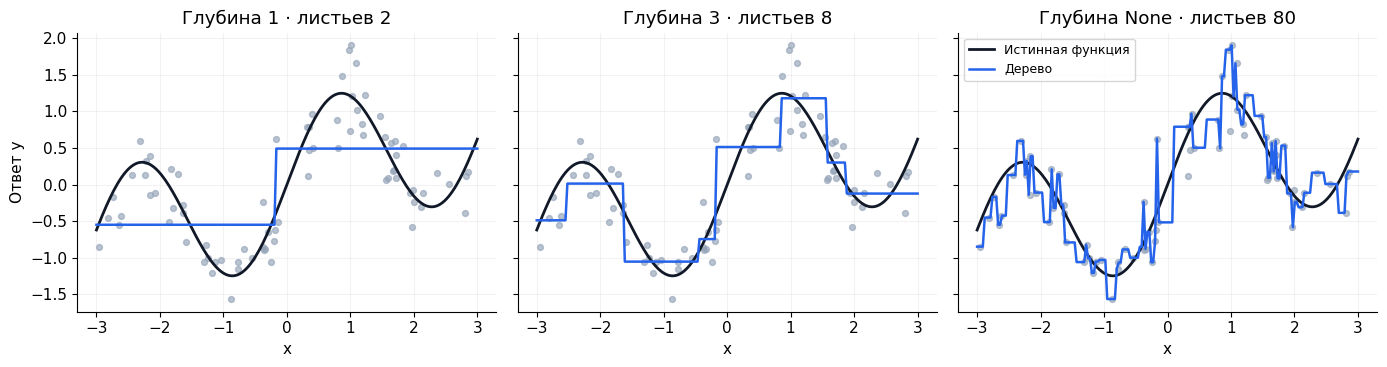

Глубина,Листьев,Train RMSE,Val RMSE
1,2,0.5591,0.6541
3,8,0.3037,0.4649
None,80,0.0000,0.4734


In [4]:
depths=[1,3,None]
base_trees={depth:DecisionTreeRegressor(max_depth=depth,random_state=SEED).fit(X_train,y_train) for depth in depths}
fig,axes=plt.subplots(1,3,figsize=(14,3.8),sharex=True,sharey=True)
rows=[]
for ax,(depth,model) in zip(axes,base_trees.items()):
    ax.scatter(X_train[:,0],y_train,s=18,color='#94a3b8',alpha=.65)
    ax.plot(X_grid[:,0],f_grid,color='#111827',lw=2,label='Истинная функция')
    ax.plot(X_grid[:,0],model.predict(X_grid),color=BLUE,lw=1.8,label='Дерево')
    ax.set(title=f'Глубина {depth} · листьев {model.get_n_leaves()}',xlabel='x')
    rows.append({'Глубина':str(depth),'Листьев':model.get_n_leaves(),
                 'Train RMSE':rmse(y_train,model.predict(X_train)), 'Val RMSE':rmse(y_val,model.predict(X_val))})
axes[0].set_ylabel('Ответ y');axes[-1].legend(loc='upper left',fontsize=9)
plt.tight_layout();plt.show();table(rows)
if stump_ready:
    own=fit_stump(X_train[:,0],y_train)
    assert np.allclose(predict_stump(own,X_grid[:,0]),base_trees[1].predict(X_grid))
    print('Ваш пень совпал с библиотечным на этой выборке.')

**Запишите:** что меняется с глубиной — число областей, величины прогнозов, train/validation ошибки? Почему глубокое дерево воспроизводит шум? …

## 2. Собрать бэггинг и рассмотреть деревья
### 2.1. Бутстрап: новые выборки из имеющихся объектов
Берём $n$ индексов из $\{0,\ldots,n-1\}$ **с возвращением**. Некоторые объекты повторятся, некоторые не попадут в выборку. Размер остаётся $n$, но число уникальных объектов обычно меньше.

Для одного объекта вероятность не попасть в bootstrap-выборку размера $n$:
$$P(\text{не выбран})=\left(1-\frac1n\right)^n\approx e^{-1}\approx0.368.$$
В среднем в ней около 63.2% уникальных объектов. Это не гарантия для каждого конкретного набора.

**Бэггинг:** независимо сгенерировать такие выборки, обучить по дереву на каждой и усреднить ответы:
$$\bar f(x)=\frac1M\sum_{m=1}^{M}T_m(x).$$
Деревья используют общий исходный train. Их нельзя считать независимыми при рассмотрении случайности исходных обучающих данных. Бутстрап не создаёт новые независимые наблюдения из неизвестного распределения.

### Задание
Реализуйте `fit_bagging(X,y,n_estimators,max_depth,min_samples_leaf,seed)`:
1. Создайте `rng=np.random.default_rng(seed)` один раз перед циклом.
2. Для каждого дерева сгенерируйте $n$ индексов с возвращением, обучите `DecisionTreeRegressor` на выбранных объектах и сохраните индексы. Задайте воспроизводимый `random_state` каждому дереву.
3. Верните `(trees, bootstrap_indices)`, где массив индексов имеет форму `(n_estimators,n)`.

Реализуйте `bagging_predict(trees,X)` — среднее прогнозов формы `(len(X),)`. Не используйте готовый `BaggingRegressor` в этих двух функциях.

In [5]:
def fit_bagging(X,y,n_estimators=40,max_depth=None,min_samples_leaf=1,seed=SEED):
    # ВАШ КОД: resampling с возвращением и обучение отдельных деревьев.
    raise NotImplementedError('Реализуйте fit_bagging')

def bagging_predict(trees,X):
    # ВАШ КОД: усредните предсказания, а не параметры деревьев.
    raise NotImplementedError('Реализуйте bagging_predict')

In [6]:
bagging_ready=False
try:
    X_small=np.arange(12,dtype=float)[:,None];y_small=np.sin(X_small[:,0])
    trees,indices=fit_bagging(X_small,y_small,n_estimators=8,max_depth=2,seed=17)
    assert len(trees)==8 and indices.shape==(8,12)
    assert np.issubdtype(indices.dtype,np.integer) and indices.min()>=0 and indices.max()<12
    assert any(len(np.unique(row))<12 for row in indices), 'Проверьте выборку с возвращением.'
    assert not np.all(indices==indices[0]), 'Не переинициализируйте RNG внутри цикла.'
    for tree,ids in zip(trees,indices):
        assert tree.tree_.n_node_samples[0]==12
        assert np.isclose(tree.tree_.value[0].ravel()[0],y_small[ids].mean()), 'Дерево должно учиться на сохранённых индексах.'
    probe=np.array([[.5],[5.5],[9.5]])
    pred=bagging_predict(trees,probe)
    assert pred.shape==(3,)
    assert np.allclose(pred,np.vstack([t.predict(probe) for t in trees]).mean(axis=0))
    trees2,ids2=fit_bagging(X_small,y_small,n_estimators=8,max_depth=2,seed=17)
    assert np.array_equal(indices,ids2) and np.allclose(pred,bagging_predict(trees2,probe))
    bagging_ready=True
    print('Проверены состав выборок, обучение на них, усреднение и воспроизводимость.')
except NotImplementedError as exc:
    print(exc)

Реализуйте fit_bagging


### 2.2. Из чего состоит ансамбль
Первый рисунок показывает кратность попадания объекта в bootstrap. Затем сравниваем три разных обученных дерева и ансамбли из первых 1, 5, 20 и 100 деревьев **одного** набора.

Все прогнозы рисуются на одинаковой сетке. Красные кресты в отдельных панелях — объекты train, не попавшие в обучение данного дерева; размер синей точки отражает кратность выбранного объекта. Чёрная линия — истинная функция.

**Гипотеза:** где деревья сильнее различаются? Сможет ли среднее полностью исправить недостаток данных или систематически грубую модель?

In [7]:
bag_trees=None
if bagging_ready:
    bag_trees,bag_indices=fit_bagging(X_train,y_train,n_estimators=100,seed=101)
    counts=np.array([np.bincount(ids,minlength=len(y_train)) for ids in bag_indices])
    order=np.argsort(X_train[:,0])
    fig,ax=plt.subplots(figsize=(12,3))
    im=ax.imshow(counts[:12,order],aspect='auto',cmap='Blues',vmin=0,vmax=counts[:12].max())
    ax.set(xlabel='Объекты train, упорядоченные по x',ylabel='Номер дерева',title='Сколько раз объект выбран для каждого дерева')
    fig.colorbar(im,ax=ax,label='Кратность');plt.tight_layout();plt.show()
    fig,axes=plt.subplots(1,3,figsize=(14,3.8),sharey=True)
    for k,ax in enumerate(axes):
        included=counts[k]>0
        ax.scatter(X_train[included,0],y_train[included],s=15+18*counts[k,included],color=BLUE,alpha=.6)
        ax.scatter(X_train[~included,0],y_train[~included],s=25,color=RED,marker='x',alpha=.6)
        ax.plot(X_grid[:,0],f_grid,color='#111827',lw=2)
        ax.plot(X_grid[:,0],bag_trees[k].predict(X_grid),color=ORANGE,lw=1.5)
        ax.set(title=f'Дерево {k+1}: уникальных объектов {included.sum()}/{len(y_train)}',xlabel='x')
    axes[0].set_ylabel('Ответ y');plt.tight_layout();plt.show()
    fig,axes=plt.subplots(2,2,figsize=(11,7),sharex=True,sharey=True)
    ensemble_rows=[]
    for ax,m in zip(axes.flat,[1,5,20,100]):
        for tree in bag_trees[:min(m,15)]:
            ax.plot(X_grid[:,0],tree.predict(X_grid),color='#94a3b8',lw=.6,alpha=.35)
        ax.plot(X_grid[:,0],f_grid,color='#111827',lw=2,label='Истинная функция')
        ax.plot(X_grid[:,0],bagging_predict(bag_trees[:m],X_grid),color=BLUE,lw=2,label='Среднее деревьев')
        score=rmse(y_val,bagging_predict(bag_trees[:m],X_val))
        ax.set(title=f'M={m} · validation RMSE={score:.3f}',xlabel='x',ylabel='Прогноз')
        ensemble_rows.append({'Деревьев':m,'Val RMSE':score})
    axes[0,0].legend(fontsize=9);plt.tight_layout();plt.show();table(ensemble_rows)
else:
    print('Сначала завершите реализацию бэггинга.')

Сначала завершите реализацию бэггинга.


### 2.3. Контрольный опыт: сто одинаковых деревьев
Если дерево и его train не изменились, копирование модели не добавляет новой информации. Запустите опыт, затем объясните отличие от bootstrap-ансамбля.

OOB (*out-of-bag*) — объекты, которые не использовались для конкретного дерева. Для OOB-прогноза объекта усредняют только те деревья, у которых он отсутствовал в train. Это даёт внутреннюю оценку качества без отдельного validation; при многократном выборе параметров по OOB всё равно нужен независимый test.

In [8]:
if bagging_ready:
    original=DecisionTreeRegressor(random_state=SEED).fit(X_train,y_train)
    repeated=bagging_predict([original]*100,X_grid)
    assert np.allclose(repeated,original.predict(X_grid))
    print('Максимальное отличие среднего 100 копий от одного дерева:',np.max(np.abs(repeated-original.predict(X_grid))))
    object_id=10
    eligible=np.flatnonzero(counts[:,object_id]==0)
    print(f'Объект {object_id}: не использован в {len(eligible)} из {len(bag_trees)} деревьев.')
    if len(eligible):
        oob_prediction=np.mean([bag_trees[k].predict(X_train[object_id:object_id+1])[0] for k in eligible])
        print(f'OOB-прогноз этого объекта: {oob_prediction:.3f}; наблюдённый ответ: {y_train[object_id]:.3f}')

**Выводы:** чем отличаются разные деревья? Почему усреднение одинаковых копий бесполезно? Что означает объект, отсутствующий в bootstrap, и можно ли использовать для его OOB-прогноза все деревья? …

На рисунках выше показан **один** обученный ансамбль. Различия его деревьев ещё не измеряют разброс всего алгоритма при изменении исходного train. Этому посвящено следующее задание.

## 3. Измерить смещение и разброс
### 3.1. Что именно случайно
Пусть $y=f(x)+\varepsilon$, $\mathbb E[\varepsilon\mid x]=0$. Зафиксируем **одну точку $x$**, но будем заново получать train и обучать алгоритм. Его прогноз $\hat f_D(x)$ меняется между запусками.

Для квадратичной ошибки на новом независимом ответе:
$$\mathbb E_{D,\varepsilon}[(\hat f_D(x)-y)^2]
=\underbrace{(\mathbb E_D\hat f_D(x)-f(x))^2}_{\text{смещение}^2}
+\underbrace{\mathbb E_D[(\hat f_D(x)-\mathbb E_D\hat f_D(x))^2]}_{\text{разброс}}
+\underbrace{\sigma^2(x)}_{\text{шум}}.$$
В ожидание по обучению включаем и внутреннюю случайность алгоритма. Смещение — отличие **среднего прогноза** от истины; разброс — изменение прогноза при новом обучении. Это не дисперсия прогнозов по разным $x$ и не train/validation gap.

### Почему помогает усреднение
В общем случае
$$\operatorname{Var}\!\left(\frac1M\sum_mT_m(x)\right)=\frac1{M^2}\sum_{i,j}\operatorname{Cov}(T_i(x),T_j(x)).$$
Если дисперсии одинаковы и равны $\tau^2$, а попарные корреляции равны $\rho$, то
$$\operatorname{Var}(\bar T(x))=\tau^2\left(\rho+\frac{1-\rho}{M}\right).$$
При $\rho=0$ получаем уменьшение в $M$ раз; при $\rho=1$ усреднение не помогает. Корреляция здесь относится к прогнозам в фиксированном $x$ по повторным обучениям, а не к корреляции кривых по сетке разных объектов.

Среднее одинаково распределённых базовых моделей сохраняет их математическое ожидание. Но отсюда не следует, что бэггинг обязательно имеет ровно то же смещение, что дерево, обученное на всём train без bootstrap.

### 3.2. Повторные независимые обучения
Готовый цикл генерирует 50 независимых train-наборов. Для каждого обучает дерево глубины 2, глубокое дерево и бэггинг из 40 глубоких деревьев. Все три метода в одном повторе используют один и тот же исходный train.

Для независимости задания от вашей реализации здесь используется библиотечный `BaggingRegressor`. Это тот же принцип: выборка с возвращением и усреднение. На выходе словарь `predictions`: массив каждого метода имеет форму **(повторы, точки сетки)**. Шум фиксированной интенсивности заново генерируется при каждом обучении.

Вычисления небольшие; уменьшите `N_REPEATS` для быстрой отладки, но итоговые оценки разброса при этом станут менее устойчивыми.

In [9]:
N_REPEATS=50
MC_TREES=40
predictions={name:np.empty((N_REPEATS,len(X_grid))) for name in ['Мелкое дерево','Глубокое дерево','Бэггинг']}
rng_mc=np.random.default_rng(2026)
for repetition in range(N_REPEATS):
    X_mc,y_mc=draw_data(80,rng_mc)
    estimators={
        'Мелкое дерево':DecisionTreeRegressor(max_depth=2,random_state=repetition),
        'Глубокое дерево':DecisionTreeRegressor(random_state=repetition),
        'Бэггинг':BaggingRegressor(estimator=DecisionTreeRegressor(),n_estimators=MC_TREES,
                                  bootstrap=True,max_samples=1.,random_state=repetition,n_jobs=1),
    }
    for name,estimator in estimators.items():
        predictions[name][repetition]=estimator.fit(X_mc,y_mc).predict(X_grid)
print('Получены массивы предсказаний:',{k:v.shape for k,v in predictions.items()})

Получены массивы предсказаний: {'Мелкое дерево': (50, 200), 'Глубокое дерево': (50, 200), 'Бэггинг': (50, 200)}


### 3.3. Посчитайте компоненты ошибки
Реализуйте `decompose(pred, f_true)`. Верните три одномерных массива по точкам сетки: `(mean_prediction, bias_squared, variance)`.

Усреднение выполняется **по оси повторов**. Для дисперсии используйте `ddof=0`. Тогда для конечного массива точно выполняется алгебраическое равенство
$$\frac1R\sum_r(\hat f_r(x)-f(x))^2=\widehat{bias}^2(x)+\widehat{variance}(x).$$
Это разложение эмпирического среднего, а не утверждение, что компоненты оценены без статистической ошибки. Для ожидаемой ошибки на новом шумном ответе дополнительно добавим известное $\sigma^2=0.35^2$.

In [10]:
def decompose(pred, f_true):
    # ВАШ КОД: три массива формы (число точек,).
    raise NotImplementedError('Реализуйте decompose')

In [11]:
decomposition_ready=False
try:
    sample=np.array([[0.,2.],[2.,4.]])
    mean,bias2,var=decompose(sample,np.array([1.,2.]))
    assert np.allclose(mean,[1,3]) and np.allclose(bias2,[0,1]) and np.allclose(var,[1,1])
    for pred in predictions.values():
        mean,bias2,var=decompose(pred,f_grid)
        assert mean.shape==bias2.shape==var.shape==f_grid.shape
        assert np.all(bias2>=0) and np.all(var>=0)
        assert np.allclose(bias2+var,((pred-f_grid)**2).mean(axis=0))
    decomposition_ready=True
    print('Проверены ось усреднения и точное разложение эмпирической ошибки.')
except NotImplementedError as exc:
    print(exc)

Реализуйте decompose


In [12]:
if decomposition_ready:
    components={name:decompose(pred,f_grid) for name,pred in predictions.items()}
    fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True,sharey=True)
    for ax,(name,pred) in zip(axes,predictions.items()):
        mean,bias2,var=components[name]
        for curve in pred[:12]:ax.plot(X_grid[:,0],curve,color=BLUE,lw=.5,alpha=.18)
        ax.fill_between(X_grid[:,0],mean-np.sqrt(var),mean+np.sqrt(var),color=BLUE,alpha=.15,label='Среднее ± std')
        ax.plot(X_grid[:,0],f_grid,color='#111827',lw=2,label='Истинная функция')
        ax.plot(X_grid[:,0],mean,color=ORANGE,lw=2,label='Средний прогноз')
        ax.set(title=name,xlabel='x')
    axes[0].set_ylabel('Прогноз');axes[-1].legend(fontsize=8)
    plt.tight_layout();plt.show()
    names=list(components)
    b=np.array([components[name][1].mean() for name in names])
    v=np.array([components[name][2].mean() for name in names])
    noise=np.full(len(names),NOISE**2)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.bar(names,b,color=ORANGE,label='Смещение²')
    ax.bar(names,v,bottom=b,color=BLUE,label='Разброс')
    ax.bar(names,noise,bottom=b+v,color='#94a3b8',label='Шум')
    ax.set(ylabel='Компоненты MSE, среднее по сетке',title='Ошибка на новом шумном ответе: эмпирическая оценка риска')
    ax.legend();plt.tight_layout();plt.show()
    table([{'Модель':name,'Смещение²':float(b[i]),'Разброс':float(v[i]),'Шум':float(noise[i]),
            'Сумма':float(b[i]+v[i]+noise[i])} for i,name in enumerate(names)])
    print(f'Отношение разброса глубокого дерева к бэггингу: {v[1]/v[2]:.2f}; деревьев в ансамбле: {MC_TREES}.')

**Как читать рисунок.** Тонкие линии — отдельные повторные обучения; оранжевая — среднее по всем 50; голубая полоса — ± одно стандартное отклонение прогнозов. Это **не доверительный интервал** и не интервал для будущего шумного ответа.

**Выводы:** что усреднение изменило сильнее — смещение или разброс? Почему отношение дисперсий не обязано равняться 40? Можно ли уменьшить шум простым увеличением числа деревьев? Почему bootstrap внутри одного train не заменил бы этот эксперимент с независимыми train? …

## 4. Настроить Random Forest
### 4.1. Что добавляется к бэггингу
Random Forest строит деревья на bootstrap-выборках и при поиске разреза **в каждом узле** рассматривает случайное подмножество признаков. `max_features` задаёт его размер. Это помогает получать различающиеся деревья, но слишком малое число кандидатов может ухудшить отдельные модели.

В одномерном примере выбирать признаки было не из чего. Теперь используем 12 признаков, из которых истинная функция зависит от первых пяти:
$$f(x)=10\sin(\pi x_1x_2)+20(x_3-0.5)^2+10x_4+5x_5.$$
Остальные семь — независимые шумовые признаки. Стандартное отклонение шума ответа — 1.5. В этом эксперименте модели получают только наблюдённые ответы, а не формулу $f$.

| Параметр | Роль |
|---|---|
| `max_depth` | Ограничивает детализацию каждого дерева |
| `min_samples_leaf` | Требует достаточно наблюдений в листе |
| `max_features` | Меняет выбор разрезов, разнообразие и силу отдельных деревьев |
| `n_estimators` | Делает усреднение стабильнее, увеличивая время и память |

Глубокие деревья — полезные кандидаты, а не гарантированно оптимальный выбор. В лесу оптимальная сложность отдельного дерева может отличаться от сложности лучшего одиночного дерева. Больше деревьев не исправляет любую ошибку признаков или ограничений.

### Протокол
800 объектов — train, 300 — validation, 300 — test. Основная метрика — RMSE. Параметры выбираем по validation; OOB рассматриваем как дополнительную диагностику, а не второй критерий для поиска удобного победителя. Test пока не используем.

In [13]:
X_rf,y_rf=make_friedman1(n_samples=1400,n_features=12,noise=1.5,random_state=2026)
X_rf_dev,X_rf_test,y_rf_dev,y_rf_test=train_test_split(X_rf,y_rf,test_size=300,random_state=SEED)
X_rf_train,X_rf_val,y_rf_train,y_rf_val=train_test_split(X_rf_dev,y_rf_dev,test_size=300,random_state=SEED)
print('Размеры:',len(y_rf_train),len(y_rf_val),len(y_rf_test))

PARAM_GRID={'max_depth':[3,8,None],'min_samples_leaf':[1,5],'max_features':[.5,1.]}
SEARCH_TREES=40
print('Конфигураций:',len(list(ParameterGrid(PARAM_GRID))))

Размеры: 800 300 300
Конфигураций: 12


### 4.2. Сравните 12 конфигураций
Реализуйте `make_forest(params, n_estimators, seed)`: верните **необученный** `RandomForestRegressor` с параметрами из `params`, заданным числом деревьев, `bootstrap=True`, `oob_score=True`, `random_state=seed`, `n_jobs=1`.

Цикл обучения и визуализации готовы. `n_jobs=1` выбран для воспроизводимой нагрузки на ноутбук; это не рекомендация всегда ограничивать параллелизм в рабочих задачах.

Затем реализуйте `choose_config(results)`: верните **копию** словаря `params` строки с минимальным `val_rmse`. При равенстве берите первую строку. Другие метрики не участвуют в этом выборе.

На тепловых картах сравните влияние глубины при разных размерах листа. Можно ли по результату одиночного дерева заранее назначить глубину леса?

In [14]:
def make_forest(params, n_estimators=SEARCH_TREES, seed=SEED):
    # ВАШ КОД: создайте модель, пока без fit.
    raise NotImplementedError('Реализуйте make_forest')

def choose_config(results):
    # ВАШ КОД: выбор только по validation RMSE.
    raise NotImplementedError('Реализуйте choose_config')

In [15]:
search_results=None
try:
    demo=make_forest({'max_depth':3,'min_samples_leaf':1,'max_features':.5},n_estimators=10,seed=7)
    assert demo.n_estimators==10 and demo.random_state==7
    assert demo.bootstrap and demo.oob_score and not hasattr(demo,'estimators_')
    fake=[{'params':{'max_depth':3},'val_rmse':2.,'train_rmse':0.},
          {'params':{'max_depth':8},'val_rmse':1.,'train_rmse':.5}]
    assert choose_config(fake)=={'max_depth':8}
    assert choose_config(fake) is not fake[1]['params']
    search_results=[]
    for params in ParameterGrid(PARAM_GRID):
        model=make_forest(params)
        start=perf_counter();model.fit(X_rf_train,y_rf_train);elapsed=perf_counter()-start
        # oob_score_ у регрессора — R²; для сравнения RMSE берём сами OOB-прогнозы.
        search_results.append({'params':params.copy(), 'val_rmse':rmse(y_rf_val,model.predict(X_rf_val)),
                               'train_rmse':rmse(y_rf_train,model.predict(X_rf_train)),
                               'oob_rmse':rmse(y_rf_train,model.oob_prediction_), 'seconds':elapsed})
except NotImplementedError as exc:
    print(exc)
if search_results is not None:
    table([{'Глубина':str(r['params']['max_depth']),'min_leaf':r['params']['min_samples_leaf'],
            'max_features':r['params']['max_features'],'Train RMSE':r['train_rmse'],
            'Val RMSE':r['val_rmse'],'OOB RMSE':r['oob_rmse'],'Время, с':r['seconds']} for r in search_results])
    selected_params=choose_config(search_results)
    assert selected_params in list(ParameterGrid(PARAM_GRID))
    print('Выбраны параметры:',selected_params)

Реализуйте make_forest


In [16]:
if search_results is not None:
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    vals=[r['val_rmse'] for r in search_results]
    for ax,mf in zip(axes,[.5,1.]):
        matrix=np.array([[next(r['val_rmse'] for r in search_results if r['params']==
                        {'max_depth':depth,'min_samples_leaf':leaf,'max_features':mf})
                          for depth in [3,8,None]] for leaf in [1,5]])
        im=ax.imshow(matrix,cmap='YlGnBu_r',vmin=min(vals),vmax=max(vals),aspect='auto')
        ax.set(xticks=[0,1,2],xticklabels=['3','8','None'],yticks=[0,1],yticklabels=['1','5'],
               xlabel='max_depth',ylabel='min_samples_leaf',title=f'max_features={mf}')
        for i in range(2):
            for j in range(3):
                color='white' if matrix[i,j] < (min(vals)+max(vals))/2 else '#111827'
                ax.text(j,i,f'{matrix[i,j]:.3f}',ha='center',va='center',color=color,fontsize=13)
    fig.colorbar(im,ax=axes,label='Validation RMSE: меньше лучше')
    plt.show()

### 4.3. Сколько деревьев достаточно?
Для выбранной конфигурации проверим `[20, 50, 100, 200]`. Для каждого размера обучим лес заново с одинаковым seed, измерим время и validation RMSE.

Зафиксируем правило до просмотра графика: выбираем **наименьшее** число деревьев, RMSE которого не хуже минимальной более чем на 1%. Это практическое правило выбора стоимости, а не статистический тест эквивалентности.

Менять правило после просмотра test нельзя. По одному измерению времени не следует делать тонкие выводы о производительности: оно зависит от машины и фоновой нагрузки.

In [17]:
selected_rf=None
size_results=None
if search_results is not None:
    size_models={};size_results=[]
    for m in [20,50,100,200]:
        model=make_forest(selected_params,n_estimators=m)
        start=perf_counter();model.fit(X_rf_train,y_rf_train);elapsed=perf_counter()-start
        size_models[m]=model
        size_results.append({'Деревьев':m,'Val RMSE':rmse(y_rf_val,model.predict(X_rf_val)),'Время, с':elapsed})
    table(size_results)
    best_rmse=min(row['Val RMSE'] for row in size_results)
    chosen_m=min(row['Деревьев'] for row in size_results if row['Val RMSE']<=1.01*best_rmse)
    selected_rf=size_models[chosen_m]
    fig,axes=plt.subplots(1,2,figsize=(11,3.8))
    axes[0].plot([r['Деревьев'] for r in size_results],[r['Val RMSE'] for r in size_results],'o-',color=BLUE)
    axes[0].axhline(1.01*best_rmse,ls='--',color=ORANGE,label='Лучший RMSE + 1%')
    axes[0].axvline(chosen_m,ls=':',color=GREEN,label=f'Выбрано {chosen_m}')
    axes[0].set(xlabel='Число деревьев',ylabel='Validation RMSE');axes[0].legend(fontsize=9)
    axes[1].plot([r['Деревьев'] for r in size_results],[r['Время, с'] for r in size_results],'o-',color=GREEN)
    axes[1].set(xlabel='Число деревьев',ylabel='Время обучения, с')
    plt.tight_layout();plt.show()
    print('Зафиксировано:',selected_params,'n_estimators=',chosen_m)

### 4.4. Финальная оценка
Сначала завершите выбор по validation. После этого установите `EVALUATE_TEST=True`.

Сравним настроенный лес с глубоким одиночным деревом и исходным лесом из 100 деревьев (`max_depth=None`, `min_samples_leaf=1`, `max_features=1.0`). Для всех моделей используем один и тот же train; выбранный лес не переобучаем на validation, чтобы сохранить сопоставимость.

Выбранная конфигурация — лучшая по нашему протоколу и ограниченному набору кандидатов, **не универсальный оптимум**. Она может не превзойти исходную модель на test; такой результат нужно объяснить, а не менять выбор задним числом.

In [18]:
EVALUATE_TEST=False
if EVALUATE_TEST and selected_rf is not None:
    baselines={
        'Одиночное дерево':DecisionTreeRegressor(random_state=SEED).fit(X_rf_train,y_rf_train),
        'Исходный лес':RandomForestRegressor(n_estimators=100,max_depth=None,min_samples_leaf=1,
                          max_features=1.0,random_state=SEED,n_jobs=1).fit(X_rf_train,y_rf_train),
        'Настроенный лес':selected_rf,
    }
    table([{'Модель':name,'Test RMSE':rmse(y_rf_test,model.predict(X_rf_test))}
           for name,model in baselines.items()])
elif selected_rf is None:
    print('Сначала выполните выбор конфигурации и числа деревьев.')
else:
    print('Test сохранён до фиксации выбора.')

Сначала выполните выбор конфигурации и числа деревьев.


**Выводы:**
- Как глубина и размер листа повлияли на качество? Что показывает сравнение `max_features=0.5` и `1.0`? …
- Совпали ли предпочтения по OOB и validation? Почему они не обязаны совпасть? …
- Какая прибавка качества оправдала увеличение числа деревьев? …
- Чем измерение разброса в задании 3 отличается от подбора модели в задании 4? …

**Дополнительно:** вычислите полную OOB-оценку собственного бэггинга из задания 2. Для объектов без единого OOB-дерева отметьте отсутствие прогноза и не подставляйте ноль. Сравните покрытие и RMSE при разном количестве деревьев.

## Материалы
- [Учебник Яндекса: ансамбли](https://contest.yandex.ru/tracks/ml/supervised-learning/ensembles-in-machine-learning) — мотивация и обсуждение параметров.
- [scikit-learn: разложение ошибки одного дерева и бэггинга](https://scikit-learn.org/stable/auto_examples/ensemble/plot_bias_variance.html) — пример повторных независимых обучений.
- [scikit-learn: ансамбли](https://scikit-learn.org/stable/modules/ensemble.html#forest) — устройство леса и параметры реализации.